In [20]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)
print("Répertoire de travail :", Path.cwd())
from src.recommender import recommend

Répertoire de travail : C:\Users\sophi\Projet_nlp_vin


In [21]:
# 1. Chargement des 600 vins et des 20 requêtes d'évaluation
wines_df = pd.read_csv("data/processed/wines_600.csv") if Path("data/processed/wines_600.csv").exists() else pd.read_csv("data/processed/wines_reference.csv")
with open("data/eval/test_queries.json", "r", encoding="utf-8") as f:
    test_queries = json.load(f)

print(f"Vins chargés : {len(wines_df)} | Requêtes de test : {len(test_queries)}")

# Construction du texte de référence par vin (description + cépage + titre)
wine_texts = (
    wines_df["title"].fillna("") + " "
    + wines_df["variety"].fillna("") + " "
    + wines_df["description"].fillna("")
).tolist()

Vins chargés : 600 | Requêtes de test : 20


In [22]:
# 2. Méthode A : Baseline TF-IDF (unigrammes + bigrammes)
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
wine_tfidf = tfidf.fit_transform(wine_texts)

def top3_tfidf(query: str) -> pd.DataFrame:
    q_vec = tfidf.transform([query])
    sims = cosine_similarity(q_vec, wine_tfidf)[0]
    top_idx = np.argsort(sims)[::-1][:3]
    return wines_df.iloc[top_idx]

In [23]:
# 3. Méthode B : Moyenne de vecteurs de mots (Word2Vec / fastText via gensim si dispo, sinon SVD lexical)
try:
    from gensim.models import Word2Vec
    tokenized_corpus = [t.lower().split() for t in wine_texts]
    w2v = Word2Vec(sentences=tokenized_corpus, vector_size=100, window=5, min_count=2, workers=2, seed=42)

    def _avg_w2v(text: str) -> np.ndarray:
        vecs = [w2v.wv[w] for w in text.lower().split() if w in w2v.wv]
        return np.mean(vecs, axis=0) if vecs else np.zeros(100, dtype=np.float32)

    wine_w2v = np.vstack([_avg_w2v(t) for t in wine_texts])
    METHOD_B_NAME = "Word2Vec (moyenne mots)"

    def top3_method_b(query: str) -> pd.DataFrame:
        q_vec = _avg_w2v(query).reshape(1, -1)
        sims = cosine_similarity(q_vec, wine_w2v)[0]
        top_idx = np.argsort(sims)[::-1][:3]
        return wines_df.iloc[top_idx]

except ImportError:
    from sklearn.decomposition import TruncatedSVD
    svd = TruncatedSVD(n_components=100, random_state=42)
    wine_lsa = svd.fit_transform(wine_tfidf)
    METHOD_B_NAME = "LSA / SVD (100 dims)"

    def top3_method_b(query: str) -> pd.DataFrame:
        q_vec = svd.transform(tfidf.transform([query]))
        sims = cosine_similarity(q_vec, wine_lsa)[0]
        top_idx = np.argsort(sims)[::-1][:3]
        return wines_df.iloc[top_idx]

In [24]:
# 4. Méthode C : Notre moteur SBERT multilingue + Blocs (Lot 3, sans filtre dur couleur)
def top3_sbert_blocks(query: str) -> pd.DataFrame:
    recs = recommend({"description": query}, k=3, wines_df=wines_df)
    rows = [r["wine"] for r in recs]
    return pd.DataFrame(rows)

In [25]:
# 5. Fonction d'évaluation : Hit@3 Couleur, Hit@3 Cépage et MRR@3 Cépage
def normalize_color(val: str) -> str:
    v = str(val or "").strip().lower()
    if v in ("rouge", "red"):
        return "red"
    if v in ("blanc", "white"):
        return "white"
    if v in ("rosé", "rose", "pink"):
        return "rose"
    if v in ("effervescent", "sparkling", "champagne"):
        return "sparkling"
    return v

def evaluate_method(name: str, predict_fn) -> dict:
    color_hits = 0
    variety_hits = 0
    mrr_variety = 0.0
    details = []

    color_col = next((c for c in ("color", "couleur", "wine_color") if c in wines_df.columns), "color")
    var_col = next((c for c in ("variety", "grape", "cepage") if c in wines_df.columns), "variety")

    for item in test_queries:
        top3 = predict_fn(item["query"])
        expected_c = normalize_color(item["expected_color"])
        expected_vs = [v.lower() for v in item["expected_varieties"]]

        pred_colors = [normalize_color(c) for c in top3[color_col].tolist()]
        pred_vars = [str(v or "").lower() for v in top3[var_col].tolist()]

        c_ok = expected_c in pred_colors
        v_rank = None
        for rank, pv in enumerate(pred_vars, start=1):
            if any(ev in pv or pv in ev for ev in expected_vs):
                v_rank = rank
                break

        if c_ok:
            color_hits += 1
        if v_rank is not None:
            variety_hits += 1
            mrr_variety += 1.0 / v_rank

        details.append({
            "id": item["id"],
            "query": item["query"],
            "expected_color": expected_c,
            "top3_colors": pred_colors,
            "color_hit": c_ok,
            "top3_varieties": top3[var_col].tolist(),
            "variety_hit": v_rank is not None,
        })

    n = len(test_queries)
    return {
        "Méthode": name,
        "Hit@3 Couleur (%)": round(100 * color_hits / n, 1),
        "Hit@3 Cépage (%)": round(100 * variety_hits / n, 1),
        "MRR@3 Cépage": round(mrr_variety / n, 3),
        "details": pd.DataFrame(details),
    }

results = [
    evaluate_method("TF-IDF (lexical)", top3_tfidf),
    evaluate_method(METHOD_B_NAME, top3_method_b),
    evaluate_method("SBERT multilingue + Blocs (Lot 3)", top3_sbert_blocks),
]

summary_df = pd.DataFrame([{k: v for k, v in r.items() if k != "details"} for r in results])
display(summary_df)

c:\Users\sophi\Projet_nlp_vin\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 742.41it/s]


,Méthode,Hit@3 Couleur (%),Hit@3 Cépage (%),MRR@3 Cépage
0,TF-IDF (lexical),85.0,60.0,0.508
1,Word2Vec (moyenne mots),75.0,35.0,0.317
2,SBERT multilingue + Blocs (Lot 3),80.0,45.0,0.325


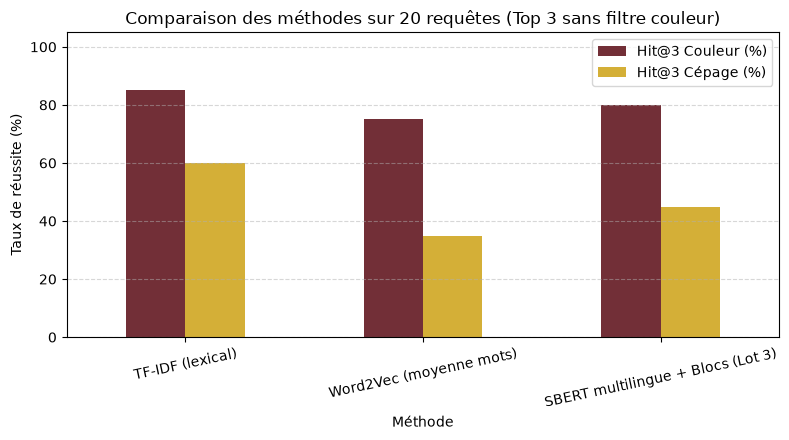

<Figure size 640x480 with 0 Axes>

In [28]:
# 6. Graphique comparatif prêt pour les slides
ax = summary_df.set_index("Méthode")[["Hit@3 Couleur (%)", "Hit@3 Cépage (%)"]].plot(
    kind="bar", figsize=(8, 4.5), ylim=(0, 105), rot=12, color=["#722F37", "#D4AF37"]
)
ax.set_title("Comparaison des méthodes sur 20 requêtes (Top 3 sans filtre couleur)")
ax.set_ylabel("Taux de réussite (%)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
from pathlib import Path


plt.tight_layout()
plt.savefig("slides/eval_comparison.png", dpi=150)
plt.show()
plt.savefig("slides/eval_comparison.png", dpi=150)
plt.show()